# 08 · Final run on the evaluator_test trips (frozen pipeline)

**Input:** the 10 reserved `evaluator_test` trips (raw `.track/.nodes/.arcs/.route`; the folder is git-ignored and is not
in the repo), and the frozen pipeline: `models/hmm_config.json` + `models/RandomForest_tuned.joblib`.
**Output:** `outputs/evaluator_results/` (per-trip and summary scores, a figure, `EVALUATOR_TEST_REPORT.md`).

**Rules followed**
* **Nothing is chosen here.** The classifier (tuned Random Forest), its hyperparameters, the candidate settings and the
  decoder parameters were all fixed before this run, from train cross-validation (notebooks 03–07). This notebook
  only reports numbers.
* **Prediction is label-free.** Each trip goes through `hmm.predict_trip`, which drops the `.route` file before
  cleaning, so the model and the decoder never see the reference route.
* **Scoring comes after.** Only then is `.route` read, to build the reference arc of each fix (the same route
  alignment as for training labels) and to compute the scores.
* Tuned LightGBM + HMM (with its own decoder from notebook 07) is reported next to it as the runner-up, for comparison only.

In [1]:
import json, os, sys, time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from pathsnap import hmm as H
from pathsnap.cleaning import clean_trip
from pathsnap.data_io import load_trip
from pathsnap.features import build_trip_features
from pathsnap.training import route_continuity

PART = "evaluator_test"
# the trips live in <root>/evaluator_test/<trip_id>/; set PATHSNAP_EVAL_ROOT, or put the folder in the repo root or next to it
roots = [Path(os.environ["PATHSNAP_EVAL_ROOT"])] if "PATHSNAP_EVAL_ROOT" in os.environ else [ROOT, ROOT.parent / "evaluator_test"]
EVAL_ROOT = next(r for r in roots if (r / PART).is_dir() and any((r / PART).iterdir()))
OUT = ROOT / "outputs" / "evaluator_results"
(OUT / "figures").mkdir(parents=True, exist_ok=True)

cfg = json.loads((ROOT / "models" / "hmm_config.json").read_text())
PIPELINES = {"RandomForest_tuned": cfg["decoder_params"], **cfg["decoder_params_other_classifier"]}
models = {n: joblib.load(ROOT / "models" / f"{n}.joblib") for n in PIPELINES}
trips = sorted(p.name for p in (EVAL_ROOT / PART).iterdir() if p.is_dir())
print(f"final classifier (frozen): {cfg['classifier']}; {len(trips)} evaluator trips: {trips}")
print("decoder parameters (frozen):", json.dumps(cfg["decoder_params"], indent=1))

final classifier (frozen): RandomForest_tuned; 10 evaluator trips: ['00000015', '00000017', '00000023', '00000030', '00000049', '00000059', '00000067', '00000073', '00000087', '00000094']
decoder parameters (frozen): {
 "beta_m": 3.740802119164323,
 "no_path_pen": 43.44637981618004,
 "uturn_pen": 17.239626086198143,
 "stop_pen": 11.321651658631374,
 "speed_pen": 5.729636264741511,
 "p_floor": 2.2740366867919638e-05,
 "use_dist": true,
 "sigma_m": 32.84125088999664
}


## 1. Predict (label-free), then score
Metrics are the same as in notebook 07: observation-level Top-1 on labelled fixes and on `label_reliable` fixes,
route continuity, and length-weighted sequence precision / recall / F1 of the predicted arcs against the reference
route arcs.

In [2]:
rows = []
for tid in trips:
    # 1) prediction from the raw files; predict_trip removes the route before anything else
    pred = {n: H.predict_trip(PART, tid, m, PIPELINES[n], root=EVAL_ROOT) for n, m in models.items()}
    # 2) scoring: reference arc per fix from the .route file
    c = clean_trip(load_trip(PART, tid, EVAL_ROOT))
    _, fx = build_trip_features(c)
    fx = fx.set_index("fix_idx")
    arcs = {tid: (c["arcs"].from_node.to_numpy(), c["arcs"].to_node.to_numpy())}
    L, R = c["arcs"].length_m.to_numpy(), set(c["route"].canonical_arc_id)
    for n, r in pred.items():
        f = r["fixes"].set_index("fix_idx")
        lab = fx.loc[f.index]
        has, rel, ta = lab.has_label.to_numpy(), lab.label_reliable.to_numpy(), lab.true_arc.to_numpy()
        for method, col in (("classifier only", "pred_arc_classifier"), ("classifier + HMM", "pred_arc_hmm")):
            pa = f[col].to_numpy()
            P = set(pa.tolist())
            inter = L[list(P & R)].sum()
            rows.append({"trip_id": tid, "classifier": n, "method": method, "fixes": len(f),
                         "labelled": int(has.sum()), "correct": int((pa == ta)[has].sum()),
                         "reliable": int(rel.sum()), "correct_reliable": int((pa == ta)[rel].sum()),
                         "route_continuity": route_continuity(pd.DataFrame({"trip_id": tid, "fix_idx": f.index,
                             "segment_id": f.segment_id.to_numpy(), "pred_arc": pa}), arcs),
                         "pred_len_m": L[list(P)].sum(), "ref_len_m": L[list(R)].sum(), "match_len_m": inter,
                         "seconds_total": r["timing"]["total_s"]})
    print(tid, "done", flush=True)
res = pd.DataFrame(rows)
res["top1"] = res.correct / res.labelled
res["top1_reliable"] = res.correct_reliable / res.reliable
res.to_csv(OUT / "per_trip.csv", index=False)

00000015 done


00000017 done


00000023 done


00000030 done


00000049 done


00000059 done


00000067 done


00000073 done


00000087 done


00000094 done


## 2. Summary
* **pooled** = over all labelled fixes of the 10 trips (long trips count more), as in the earlier reports.
* **trip average** = each trip counts the same.
* Route continuity is pooled over fix pairs; sequence P / R / F1 are pooled over arc length.

In [3]:
def summarise(g):
    prec, rec = g.match_len_m.sum() / g.pred_len_m.sum(), g.match_len_m.sum() / g.ref_len_m.sum()
    return pd.Series({"Top-1 pooled": g.correct.sum() / g.labelled.sum(),
                      "Top-1 pooled (reliable)": g.correct_reliable.sum() / g.reliable.sum(),
                      "Top-1 trip average": g.top1.mean(), "worst trip": g.top1.min(), "best trip": g.top1.max(),
                      "route continuity (trip average)": g.route_continuity.mean(),
                      "sequence precision": prec, "sequence recall": rec, "sequence F1": 2 * prec * rec / (prec + rec),
                      "seconds per trip (mean)": g.seconds_total.mean()})
summary = res.groupby(["classifier", "method"], sort=False).apply(summarise, include_groups=False)
summary.to_csv(OUT / "summary.csv")
summary.round(4).T

classifier                      RandomForest_tuned                   \
method                             classifier only classifier + HMM   
Top-1 pooled                                0.8688           0.9616   
Top-1 pooled (reliable)                     0.8690           0.9619   
Top-1 trip average                          0.9202           0.9643   
worst trip                                  0.7140           0.8899   
best trip                                   0.9913           0.9996   
route continuity (trip average)             0.9372           0.9661   
sequence precision                          0.9029           0.9883   
sequence recall                             0.9733           0.9772   
sequence F1                                 0.9368           0.9827   
seconds per trip (mean)                     0.8711           0.8711   

classifier                       LightGBM_tuned                   
method                          classifier only classifier + HMM  
Top-1 pooled                             0.8711           0.9617  
Top-1 pooled (reliable)                  0.8713           0.9620  
Top-1 trip average                       0.9230           0.9641  
worst trip                               0.7151           0.8899  
best trip                                0.9947           0.9996  
route continuity (trip average)          0.9426           0.9655  
sequence precision                       0.9081           0.9878  
sequence recall                          0.9740           0.9772  
sequence F1                              0.9399           0.9824  
seconds per trip (mean)                  0.8897           0.8897

In [4]:
per_trip = res.pivot_table(index="trip_id", columns=["classifier", "method"], values="top1")
per_trip.insert(0, "fixes", res.groupby("trip_id").fixes.first())
per_trip.round(4)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_19528\4123201340.py:2: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  per_trip.insert(0, "fixes", res.groupby("trip_id").fixes.first())


classifier fixes   LightGBM_tuned                 RandomForest_tuned  \
method           classifier + HMM classifier only   classifier + HMM   
trip_id                                                                
00000015    6854           0.9418          0.7151             0.9428   
00000017    1346           0.9673          0.9428             0.9658   
00000023     458           0.9629          0.9432             0.9672   
00000030     654           0.8899          0.8394             0.8899   
00000049    2642           0.9996          0.9947             0.9996   
00000059    1031           0.9796          0.9661             0.9806   
00000067     916           0.9596          0.9487             0.9596   
00000073    1144           0.9886          0.9816             0.9878   
00000087    1399           0.9964          0.9621             0.9971   
00000094    3230           0.9551          0.9365             0.9523   

classifier                  
method     classifier only  
trip_id                     
00000015            0.7140  
00000017            0.9413  
00000023            0.9432  
00000030            0.8257  
00000049            0.9913  
00000059            0.9622  
00000067            0.9520  
00000073            0.9799  
00000087            0.9593  
00000094            0.9331

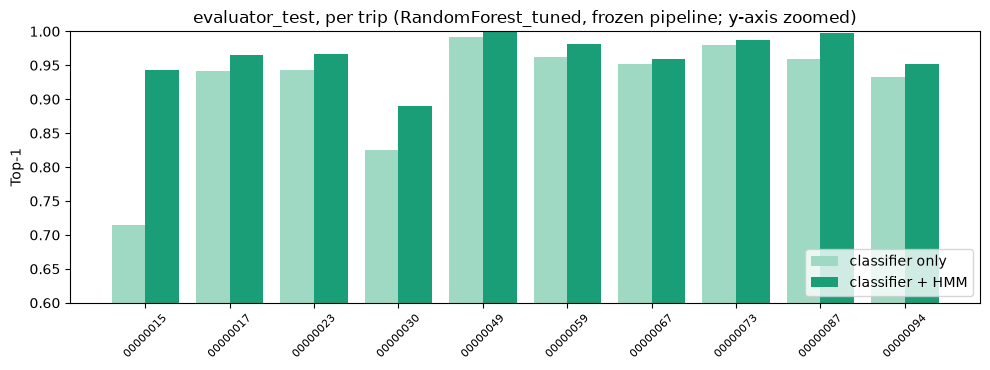

In [5]:
fin = res[res.classifier == cfg["classifier"]].pivot(index="trip_id", columns="method", values="top1")
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(fin))
ax.bar(x - 0.2, fin["classifier only"], 0.4, color="#9fd8c3", label="classifier only")
ax.bar(x + 0.2, fin["classifier + HMM"], 0.4, color="#1a9e77", label="classifier + HMM")
ax.set_xticks(x, fin.index, rotation=45, fontsize=8)
ax.set_ylim(0.6, 1.0); ax.set_ylabel("Top-1"); ax.legend(loc="lower right")
ax.set_title(f"evaluator_test, per trip ({cfg['classifier']}, frozen pipeline; y-axis zoomed)")
fig.tight_layout(); fig.savefig(OUT / "figures" / "per_trip_top1.png", dpi=150)

## 3. Write `EVALUATOR_TEST_REPORT.md`

In [6]:
s = summary.loc[(cfg["classifier"], "classifier + HMM")]
s0 = summary.loc[(cfg["classifier"], "classifier only")]
L = ["# PathSnap: final run on the evaluator_test trips", "",
     "Auto-generated by `notebooks/08_evaluator_test.ipynb`. Frozen pipeline: "
     f"**{cfg['classifier']} + HMM** with the decoder from `models/hmm_config.json`. Nothing was chosen or tuned on these "
     "trips: every choice was made on train cross-validation before this run. Prediction uses only `.track`, `.nodes` "
     "and `.arcs` (`hmm.predict_trip`); `.route` is read afterwards, for scoring only.", "",
     f"**Result:** Top-1 {s['Top-1 pooled']:.4f} with the HMM vs {s0['Top-1 pooled']:.4f} for the classifier alone "
     f"(pooled over {int(res[res.classifier == cfg['classifier']].groupby('trip_id').labelled.first().sum()):,} labelled fixes of "
     f"{len(trips)} trips).", "",
     "## Summary", "", summary.round(4).to_markdown(), "",
     "## Top-1 per trip", "", per_trip.round(4).to_markdown(), "",
     "![per_trip_top1](figures/per_trip_top1.png)", ""]
(OUT / "EVALUATOR_TEST_REPORT.md").write_text("\n".join(L), encoding="utf-8")
print("wrote", OUT / "EVALUATOR_TEST_REPORT.md")

wrote C:\College\sem-v\ml\ml_hackathon\PATHSNAP\outputs\evaluator_results\EVALUATOR_TEST_REPORT.md
